In [177]:
# import dependencies
import pandas as pd
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import PCA
import numpy as np
import matplotlib.pyplot as plt

In [178]:
# load in training data
path = "./data/text/train.json"
classes = ['anger','anticipation','disgust','fear','joy','love','optimism','pessimism','sadness','surprise','trust']
df = pd.read_json(path,lines=True)

df.head()

,ID,Tweet,anger,anticipation,disgust,fear,joy,love,optimism,pessimism,sadness,surprise,trust
0,2017-En-30866,A #new day to #live and #smile. Hope all the #...,False,False,False,False,True,False,True,False,False,False,False
1,2017-En-20244,#India is sponsoring terrorism in #Balochistan...,False,False,False,True,False,False,False,False,False,False,False
2,2017-En-41317,Sejejs says Cibulskis missed time in 3rd perio...,True,False,False,False,False,False,False,False,True,False,False
3,2017-En-30329,Punchline king is back! @Paedeezy 🔥🔥🔥🔥🔥🔥🔥💯💯💯 #...,False,False,False,False,True,False,True,False,False,False,False
4,2017-En-10714,@BarackObama I love Lizzy Warren's latest rage...,True,False,False,False,True,True,False,False,False,False,False


In [179]:
# problem: many/most entries have multiple classes, when our classification system can only handle single-classed entries
# potential solutions:
    # remove all entries with multiple classes (removes a lot of data, but ensures data purity)
    # remove all entries with multiple of the 4 selected classes (retains more, but with less strongly classes entries)
    # arbitrarily select one of the classes as the class for that entry (retains all entries but loses class information)
# the assignment instructs that we should obtain the token (feature) counts and TF-IDF feature (counts) before selecting 4 classes, though
# so I will first obtain those and *then* prune the dataset down to 4 classes

In [180]:
# obtain the token count vectors
vectorizer = CountVectorizer() # As directed, using the default parameters
token_counts = vectorizer.fit_transform(df["Tweet"])
print(token_counts.shape) # (3000, 9579), means the vector token_counts has dimensionality 9579 (the number of unique words in the dataset)

(3000, 9579)


In [181]:
# obtain the tfidf feature vectors
vectorizer = TfidfVectorizer() # default params
tfidf_features = vectorizer.fit_transform(df["Tweet"])
features = vectorizer.get_feature_names_out() # labels for dataframe, technically unnecessary
print(tfidf_features.shape) # (3000, 9579), for the same reason as above

(3000, 9579)


In [182]:
# picking four classes that I think will be separable
targets = ['anger','anticipation','trust','pessimism']
keys = df.keys()
tfidf_array = tfidf_features.toarray()
counts_array = token_counts.toarray()
# perform dimensionality reduction, down to dimensionality = 2
# first, remove all entries that are not one of the target classes, and all entries that are multiple of the target classes
reduced_tfidf = []
reduced_counts = []
reduced_classes = []
reduced_tweets = []
double_targets = 0
non_targets = 0
for i in range(3000):
    entry = df.iloc[i]
    counts = counts_array[i]
    tfidf = tfidf_array[i]
    target_count = 0
    this = ""
    for target in targets:
        if entry[target]:
            target_count += 1
            this = target
    if target_count == 1:
        reduced_tfidf.append(tfidf)
        reduced_counts.append(counts)
        reduced_classes.append(targets.index(this))
        reduced_tweets.append(entry["Tweet"])
    elif target_count > 1:
        double_targets += 1
    else:
        non_targets += 1

print("Remaining targets: " + str(len(reduced_classes)))
print("Doubled targets: " + str(double_targets))
print("Non-targets: " + str(non_targets))



Remaining targets: 1531
Doubled targets: 247
Non-targets: 1222


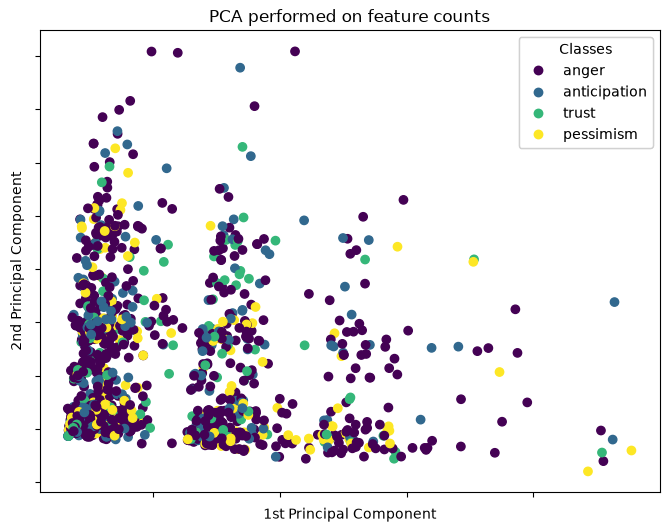

In [183]:
# This retains most of the data while removing items that would not be useful for this class based analysis
# Now, dimensionality reduction can actually be performed
# PCA dimensionality reduction on feature counts
counts_df = pd.DataFrame(data=np.array(reduced_counts), columns=features)
counts_pca = PCA(n_components=2).fit_transform(counts_df)

# display results
count_fig = plt.figure(1, figsize=(8, 6))
count_ax = count_fig.add_subplot(111)
count_scatter = count_ax.scatter(
    counts_pca[:, 0],
    counts_pca[:, 1],
    c=reduced_classes
)

count_ax.set(
    title="PCA performed on feature counts",
    xlabel="1st Principal Component",
    ylabel="2nd Principal Component"
)

count_ax.xaxis.set_ticklabels([])
count_ax.yaxis.set_ticklabels([])

count_legend = count_ax.legend(
    count_scatter.legend_elements()[0],
    targets,
    loc="upper right",
    title="Classes",
)

count_ax.add_artist(count_legend)

plt.show()
# unfortunately, there are no visually seperable classes. repeating this test with other selected classes does not change this result,
# although it can make the unidentified pattern the PCA did find appear more strongly

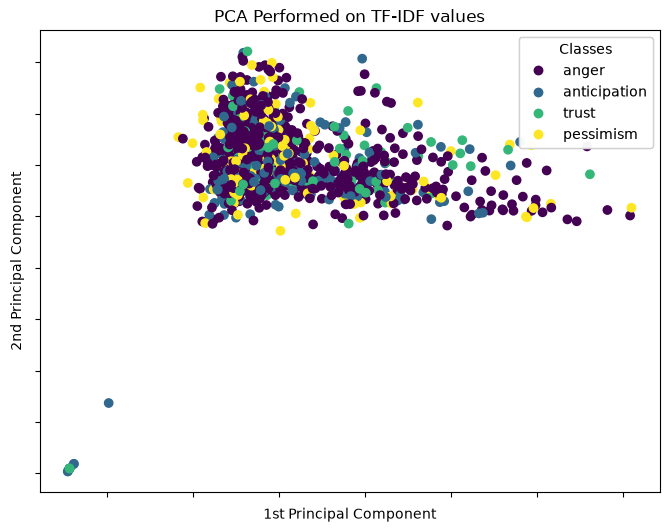

Low PC1 Tweets
Sejejs says Cibulskis missed time in 3rd period due to an injury. Wouldn't comment on how serious it is. Apparently not a doctor.
@BarackObama I love Lizzy Warren's latest rage against Wall Street.
@simondawkins23 @Titchlar81 clicked the wrong side was fuming 😭
@wwcummings @USATODAY this individual is clearly trying 2 #intimidate this #LEO I see an issue here. STOP CAUSING ISSUES by pushing limits!!
i is sad
Watch this amazing live.ly broadcast by @swagrman_fan  #musically
Watch this amazing live.ly broadcast by @maisiev  #musically
Watch this amazing live.ly broadcast by @brooke_bridges  #musically
Watch this amazing live.ly broadcast by @kana_blender  #musically

Lowest PC1 Tweet
Watch this amazing live.ly broadcast by @kana_blender  #musically


High PC2 Tweets
Sejejs says Cibulskis missed time in 3rd period due to an injury. Wouldn't comment on how serious it is. Apparently not a doctor.
@delta correction 26 ppl. Checked in. Standing at the gate. &amp; Flt 1449 took 

In [184]:
# PCA dimensionality reduction on feature tfidf values
tfidf_df = pd.DataFrame(data=np.array(reduced_tfidf), columns=features)
tfidf_pca = PCA(n_components=2).fit_transform(tfidf_df)

# display results
tfidf_fig = plt.figure(1, figsize=(8, 6))
tfidf_ax = tfidf_fig.add_subplot(111)
tfidf_scatter = tfidf_ax.scatter(
    tfidf_pca[:, 0],
    tfidf_pca[:, 1],
    c=reduced_classes
)

tfidf_ax.set(
    title="PCA Performed on TF-IDF values",
    xlabel="1st Principal Component",
    ylabel="2nd Principal Component"
)

tfidf_ax.xaxis.set_ticklabels([])
tfidf_ax.yaxis.set_ticklabels([])

tfidf_legend = tfidf_ax.legend(
    tfidf_scatter.legend_elements()[0],
    targets,
    loc="upper right",
    title="Classes",
)

tfidf_ax.add_artist(tfidf_legend)

plt.show()
#unfortunately, there are no visually seperable classes
# the following should identify the outliers in the top corner
tfidf_pca_df = pd.DataFrame(tfidf_pca,columns=['PC1','PC2'])
low_index = 0
lowest = 0

print("Low PC1 Tweets")
for i in range(len(reduced_tweets)):
    entry = tfidf_pca_df.iloc[i]
    if entry['PC1'] < lowest:
        lowest = entry['PC1']
        print(reduced_tweets[i])
        low_index = i
print()
print("Lowest PC1 Tweet")
print(reduced_tweets[low_index])

high_index = 0
highest = 0
print()
print()
print("High PC2 Tweets")
for i in range(len(reduced_tweets)):
    entry = tfidf_pca_df.iloc[i]
    if entry['PC2'] > highest:
        highest = entry['PC2']
        print(reduced_tweets[i])
        high_index = i
print()
print("Highest PC2 Tweet")
print(reduced_tweets[high_index])

In [185]:
# After viewing the outliers, it appears that there are a number of spam tweets with near-identical text. However,
# removing them resulted in the same plot, just zoomed in to the cluster in the top right of the image

In [186]:
# for the sake of experimentation, I repeated the above but pruned the dataset down to my 4 selected classes
# before deriving the feature counts and tfidf values
# obtain the token count vectors
plt.clf()
vectorizer = CountVectorizer() # As directed, using the default parameters
token_counts = vectorizer.fit_transform(reduced_tweets)
print(token_counts.shape) # (1698, 6516), means the vector token_counts has dimensionality 6516 (the number of unique words in the dataset)

(1531, 6065)


<Figure size 640x480 with 0 Axes>

In [187]:
# obtain the tfidf feature vectors
vectorizer = TfidfVectorizer() # default params
tfidf_features = vectorizer.fit_transform(reduced_tweets)
features = vectorizer.get_feature_names_out() # labels for dataframe, technically unnecessary
print(tfidf_features.shape) # (1698, 6516), for the same reason as above

(1531, 6065)


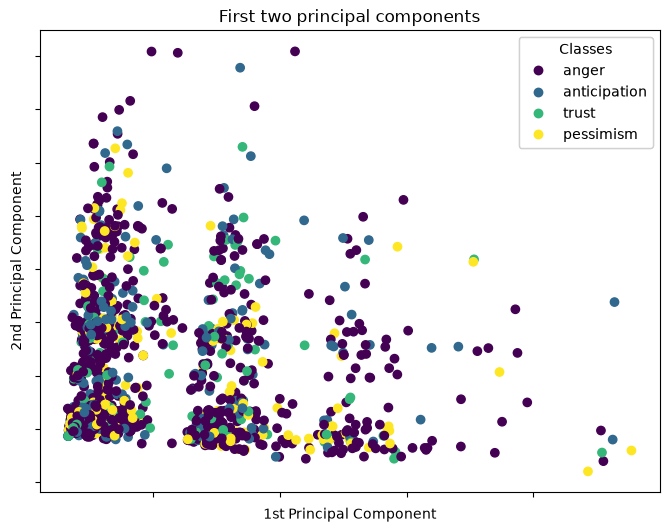

In [188]:
# This retains most of the data while removing items that would not be useful for this class based analysis
# Now, dimensionality reduction can actually be performed
# PCA dimensionality reduction on feature counts
counts_df = pd.DataFrame(data=token_counts.toarray(), columns=features)
counts_pca = PCA(n_components=2).fit_transform(counts_df)

# display results
count_fig = plt.figure(1, figsize=(8, 6))
count_ax = count_fig.add_subplot(111)
count_scatter = count_ax.scatter(
    counts_pca[:, 0],
    counts_pca[:, 1],
    c=reduced_classes
)

count_ax.set(
    title="First two principal components",
    xlabel="1st Principal Component",
    ylabel="2nd Principal Component"
)

count_ax.xaxis.set_ticklabels([])
count_ax.yaxis.set_ticklabels([])

count_legend = count_ax.legend(
    count_scatter.legend_elements()[0],
    targets,
    loc="upper right",
    title="Classes",
)

count_ax.add_artist(count_legend)

plt.show()
# unfortunately, there are no visually seperable classes. repeating this test with other selected classes does not change this result,
# although it can make the unidentified pattern the PCA did find appear more strongly
# notably identical to the first attempt, which makes sense, since this is just counts that dont take other entries into account

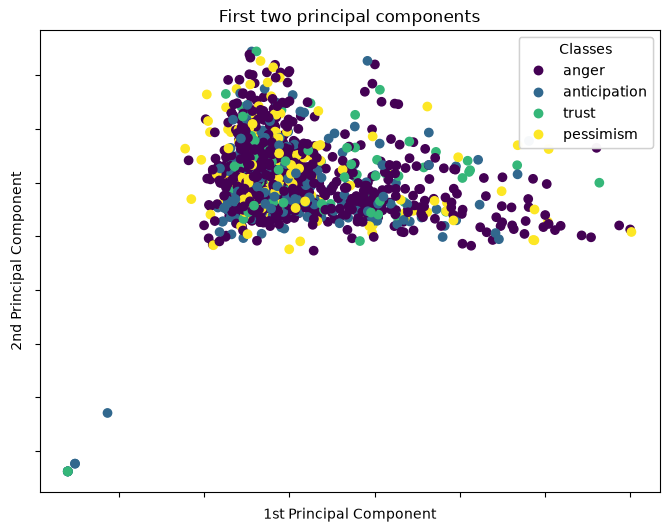

In [189]:
# PCA dimensionality reduction on feature tfidf values
tfidf_df = pd.DataFrame(data=tfidf_features.toarray(), columns=features)
tfidf_pca = PCA(n_components=2).fit_transform(tfidf_df)

# display results
tfidf_fig = plt.figure(1, figsize=(8, 6))
tfidf_ax = tfidf_fig.add_subplot(111)
tfidf_scatter = tfidf_ax.scatter(
    tfidf_pca[:, 0],
    tfidf_pca[:, 1],
    c=reduced_classes
)

tfidf_ax.set(
    title="First two principal components",
    xlabel="1st Principal Component",
    ylabel="2nd Principal Component"
)

tfidf_ax.xaxis.set_ticklabels([])
tfidf_ax.yaxis.set_ticklabels([])

tfidf_legend = tfidf_ax.legend(
    tfidf_scatter.legend_elements()[0],
    targets,
    loc="upper right",
    title="Classes",
)

tfidf_ax.add_artist(tfidf_legend)

plt.show()
#unfortunately, there are no visually seperable classes
# nearly identical to the first one, but it is slightly different since the weights change slightly with the removal of some of the context

